In [1]:
%pip install -r ../requirements.txt

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 4.2 MB/s eta 0:00:03
   ------- -------------------------------- 1.8/9.3 MB 3.9 MB/s eta 0:00:02
   ----------- ---------------------------- 2.6/9.3 MB 3.9 MB/s eta 0:00:02
   -------------- ------------------------- 3.4/9.3 MB 3.9 MB/s eta 0:00:02
   --------------------- ------------------ 5.0/9.3 MB 4.4 MB/s eta 0:00:01
   ---------------------- ----------------- 5.2/9.3 MB 4.5 MB/s eta 0:00:01
   ------------------------ --------------- 5.8/9.3 MB 3.7 MB/s eta 0:00:01
   ----------------------------- ---------- 6.8/9.3 MB 3.8 MB/s eta 0:00:01
   ------------------------------------- -- 8.7/9.3 MB 4.2 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 4.2 MB/s  0:00:02
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? 

In [2]:
import datasets
class RottenTomatoesMovieReview(datasets.GeneratorBasedBuilder):
    """Cornell Rotten Tomatoes movie reviews dataset."""

    VERSION = datasets.Version("1.0.0") 

    
    def _split_generators(self, dl_manager):
        """Downloads Rotten Tomatoes sentences."""
        archive  = dl_manager.download_and_extract("https://huggingface.co/datasets/cornell-movie-review-data/resolve/main/rotten_tomatoes.zip")
        return [
            datasets.SplitGenerator(
                name=datasets.Split.TRAIN,
                gen_kwargs={"split_key": "train", "files": dl_manager.iter_archive(archive)},
            ),
            datasets.SplitGenerator(
                name=datasets.Split.VALIDATION,
                gen_kwargs={"split_key": "validation", "files": dl_manager.iter_archive(archive)},
            ),
            datasets.SplitGenerator(
                name=datasets.Split.TEST,
                gen_kwargs={"split_key": "test", "files": dl_manager.iter_archive(archive)},
            ),
        ]

m:\Coding\Convolutional Neural Networks for Sentence Classification\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Number of samples in the entire dataset
import pandas as pd
df_train = pd.read_parquet("hf://datasets/cornell-movie-review-data/rotten_tomatoes/train.parquet")
print(f"Number of samples in the training dataset: {len(df_train)}")
df_test = pd.read_parquet("hf://datasets/cornell-movie-review-data/rotten_tomatoes/test.parquet")
print(f"Number of samples in the test dataset: {len(df_test)}")
df_validation = pd.read_parquet("hf://datasets/cornell-movie-review-data/rotten_tomatoes/validation.parquet")
print(f"Number of samples in the validation dataset: {len(df_validation)}")
df = pd.concat([df_train, df_test, df_validation], ignore_index=True)
num_samples = len(df)
print(f"Number of samples in the entire dataset: {num_samples}")
sample_len = len(df.iloc[0]['text'])
print(f"Length of the first sample: {sample_len}")
avg_len = df['text'].apply(len).mean()
print(f"Average length of samples in the entire dataset: {avg_len}")
print("\n")
print("\n")

# Classes or Targets in the dataset
classes = df['label'].unique()
print(f"Classes in the dataset: {classes}")

# Is class balance count or bar chart
class_counts = df['label'].value_counts()
print(f"Class counts in the dataset:\n{class_counts}")

Number of samples in the training dataset: 8530
Number of samples in the test dataset: 1066
Number of samples in the validation dataset: 1066
Number of samples in the entire dataset: 10662
Length of the first sample: 177
Average length of samples in the entire dataset: 114.1591633839805




Classes in the dataset: [1 0]
Class counts in the dataset:
label
1    5331
0    5331
Name: count, dtype: int64


In [4]:
# Remove rows with missing reviews or labels
df = df.dropna(subset=["text", "label"])

# Remove duplicate rows
df = df.drop_duplicates(subset=["text", "label"])


# Keep only positive and negative reviews
df = df[df["label"].isin([0, 1])]

print(df["label"].value_counts())

label
1    5331
0    5331
Name: count, dtype: int64


In [5]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Extract text and labels
X_train = df_train["text"].astype(str)
y_train = df_train["label"]

# Build the baseline model
model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            stop_words="english",
            max_features=20000,
            ngram_range=(1, 2)
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

# Train
model.fit(X_train, y_train)

print("Training completed!")

Training completed!


In [6]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

X_val = df_validation["text"].astype(str)
y_val = df_validation["label"]

# Predict
val_predictions = model.predict(X_val)

# Metrics
print("Validation Accuracy:",
      accuracy_score(y_val, val_predictions))

print("\nClassification Report:")
print(classification_report(y_val, val_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, val_predictions))

Validation Accuracy: 0.7429643527204502

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.75      0.75       533
           1       0.75      0.73      0.74       533

    accuracy                           0.74      1066
   macro avg       0.74      0.74      0.74      1066
weighted avg       0.74      0.74      0.74      1066


Confusion Matrix:
[[402 131]
 [143 390]]


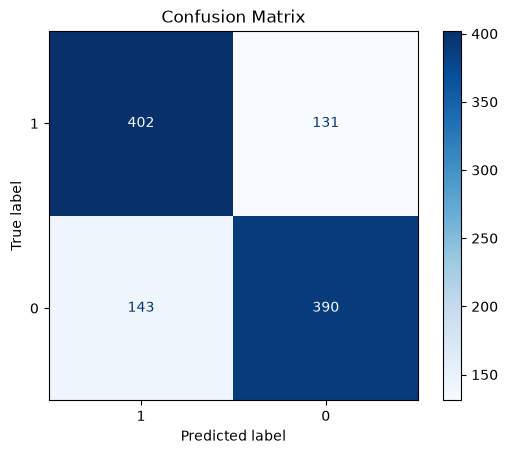

In [17]:
# Confusion matrix visualization
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_val, val_predictions)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=df["label"].unique())
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()

In [23]:
import numpy as np

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.svm import LinearSVC

# Step 1: Convert text into binary word features
vectorizer = CountVectorizer(
    binary=True,
    ngram_range=(1, 2),
    min_df=2,
    max_features=200000,
    dtype=np.float64
)
X_train_text = df_train["text"].astype(str)
y_train = df_train["label"]
X_train = vectorizer.fit_transform(X_train_text)
y_train = df_train["label"].to_numpy(dtype=int)
y_val = df_validation["label"].to_numpy(dtype=int)
y_test = df_test["label"].to_numpy(dtype=int)

# Step 2: Calculate Naive Bayes log-count ratios
alpha = 1.0

positive_counts = np.asarray(
    X_train[y_train == 1].sum(axis=0)
).ravel()

negative_counts = np.asarray(
    X_train[y_train == 0].sum(axis=0)
).ravel()

# Laplace smoothing
positive_probs = positive_counts + alpha
negative_probs = negative_counts + alpha

positive_probs /= positive_probs.sum()
negative_probs /= negative_probs.sum()

# Positive values favor positive sentiment;
# negative values favor negative sentiment.
r = np.log(positive_probs / negative_probs)

# Step 3: Reweight the features
X_train_nb = X_train.multiply(r).tocsr()

# Step 4: Train the linear SVM
svm = LinearSVC(
    C=0.1,
    max_iter=5000,
    random_state=42
)

svm.fit(X_train_nb, y_train)

print("NBSVM training completed!")
print("Vocabulary size:", len(vectorizer.vocabulary_))

NBSVM training completed!
Vocabulary size: 24083


In [24]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

X_val_text = df_validation["text"].astype(str)
X_val = vectorizer.transform(X_val_text)
X_val_nb = X_val.multiply(r).tocsr()
y_val = df_validation["label"].to_numpy(dtype=int)

val_predictions = svm.predict(X_val_nb)

print("Validation accuracy:",
      accuracy_score(y_val, val_predictions))

print("Validation macro F1:",
      f1_score(y_val, val_predictions, average="macro"))

print("\nClassification report:")
print(classification_report(
    y_val,
    val_predictions,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_val, val_predictions, labels=[0, 1]))

Validation accuracy: 0.7701688555347092
Validation macro F1: 0.7701233396500933

Classification report:
              precision    recall  f1-score   support

    Negative       0.76      0.78      0.77       533
    Positive       0.78      0.76      0.77       533

    accuracy                           0.77      1066
   macro avg       0.77      0.77      0.77      1066
weighted avg       0.77      0.77      0.77      1066

Confusion matrix:
[[418 115]
 [130 403]]


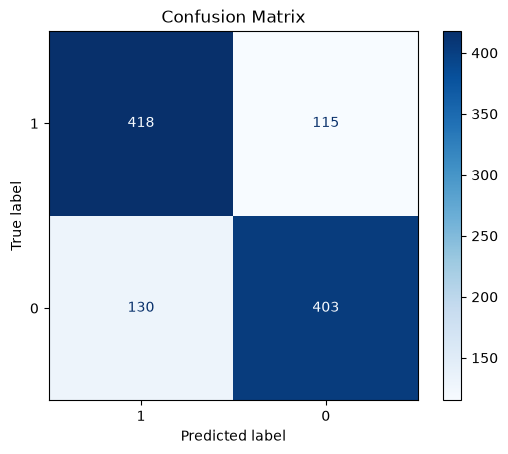

In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_val, val_predictions)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=df["label"].unique())
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()